# 1. Credit Card Fraud Detection Using Machine Learning

A Machine Learning Project for Detecting Fraudulent Credit Card Transactions


## 1.A) Project Overview

Credit card fraud is a major challenge for financial institutions and payment service providers. Fraudulent transactions can cause financial losses for customers and businesses.

Machine Learning can help identify suspicious transaction patterns and classify transactions as legitimate or fraudulent.

In this project, we will develop and evaluate machine learning models to detect fraudulent credit card transactions using a publicly available dataset.


## 1.B) Problem Statement

The objective of this project is to build a machine learning model that can identify fraudulent credit card transactions.

The main challenge is that fraudulent transactions represent a very small proportion of all transactions. This creates an imbalanced classification problem.

The model should identify as many fraudulent transactions as possible while keeping false alarms at a reasonable level.


## 1.C) Project Objectives

1. Load and understand the credit card transaction dataset.
2. Perform exploratory data analysis (EDA).
3. Prepare and transform the data.
4. Train machine learning classification models.
5. Handle class imbalance.
6. Tune model parameters and decision thresholds.
7. Evaluate model performance using appropriate metrics.
8. Compare models and select the best-performing model.
9. Save the trained model for future use.


## 1.D) Tools and Technologies

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib
- Kaggle Dataset


# 2. Dataset Description

## 2.A) Dataset Source

This project uses the Credit Card Fraud Detection dataset available on Kaggle.

Dataset link: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

The dataset contains credit card transactions made by European cardholders in September 2013.


## 2.B) Dataset Information

The dataset contains 284,807 transactions and 31 columns.

- `Time`: Seconds elapsed between each transaction and the first transaction.
- `Amount`: Transaction amount.
- `V1` to `V28`: Numerical features obtained through Principal Component Analysis (PCA).
- `Class`: Target variable (0 = legitimate, 1 = fraudulent).

The dataset contains only 492 fraudulent transactions, making it highly imbalanced.


# 3. Import Libraries and Load Dataset

## 3.A) Install Required Libraries

In [1]:
!pip install -q kaggle


## 3.B) Import Libraries

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


## 3.C) Download Dataset from Kaggle

Run the cell below. Colab will ask for your Kaggle username and API key. You can obtain these from your Kaggle account settings. Keep your API key private.


In [3]:
import os
from getpass import getpass

# Paste your NEW Kaggle API token when prompted.
# The token is hidden while you type/paste and is not displayed in the notebook output.
kaggle_token = getpass("Enter your new Kaggle API token: ")

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

# Download and extract the dataset using the Kaggle CLI.
!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content
!unzip -o /content/creditcardfraud.zip -d /content/creditcardfraud

print("Dataset downloaded and extracted successfully.")


Enter your new Kaggle API token: ··········
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 269MB/s]

Archive:  /content/creditcardfraud.zip
  inflating: /content/creditcardfraud/creditcard.csv  
Dataset downloaded and extracted successfully.


## 3.D) Load Dataset

In [4]:
dataset_path = "/content/creditcardfraud/creditcard.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3.E) Display Dataset Information

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 3.F) Display Statistical Summary

In [6]:
display(df.describe())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


# 4. Exploratory Data Analysis (EDA)

## 4.A) Check Missing Values

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0


## 4.B) Check Duplicate Records

In [8]:
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 1081


## 4.C) Analyze Target Class Distribution

In [9]:
class_counts = df["Class"].value_counts().sort_index()
print(class_counts)
print("\nClass percentages:")
print(df["Class"].value_counts(normalize=True).sort_index() * 100)


Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


## 4.D) Visualize Legitimate and Fraudulent Transactions

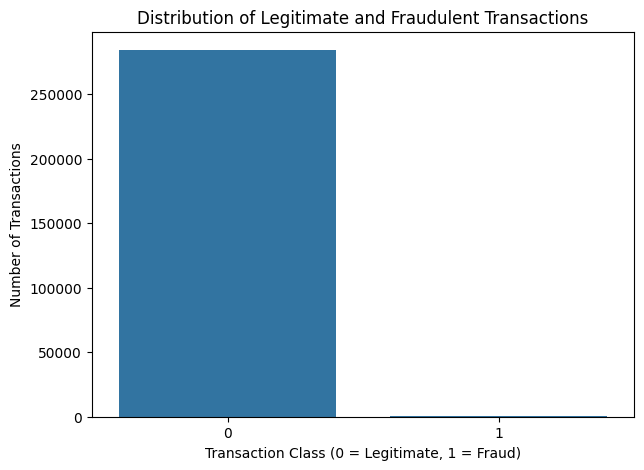

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()


## 4.E) Visualize Class Distribution as a Pie Chart

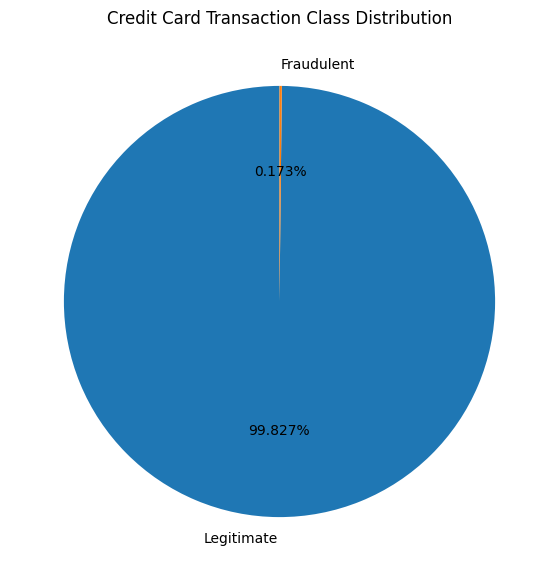

In [11]:
plt.figure(figsize=(7, 7))
plt.pie(
    class_counts.values,
    labels=["Legitimate", "Fraudulent"],
    autopct="%1.3f%%",
    startangle=90
)
plt.title("Credit Card Transaction Class Distribution")
plt.show()


## 4.F) Analyze Transaction Amounts

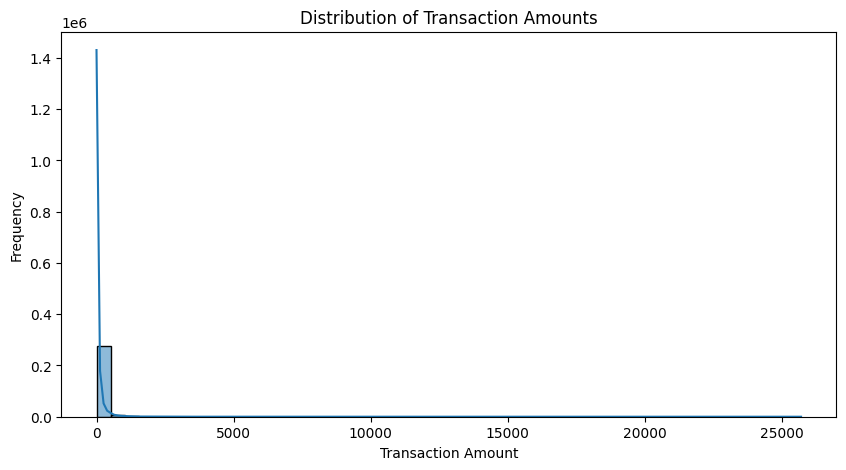

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Amount", bins=50, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()


## 4.G) Compare Transaction Amounts by Class

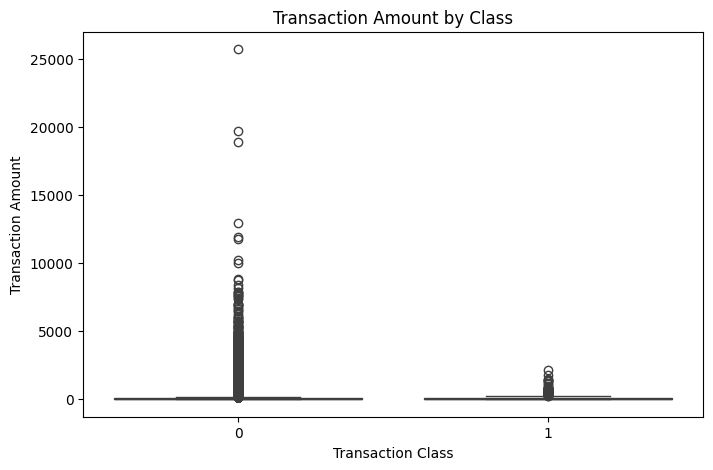

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.show()


## 4.H) Correlation Heatmap

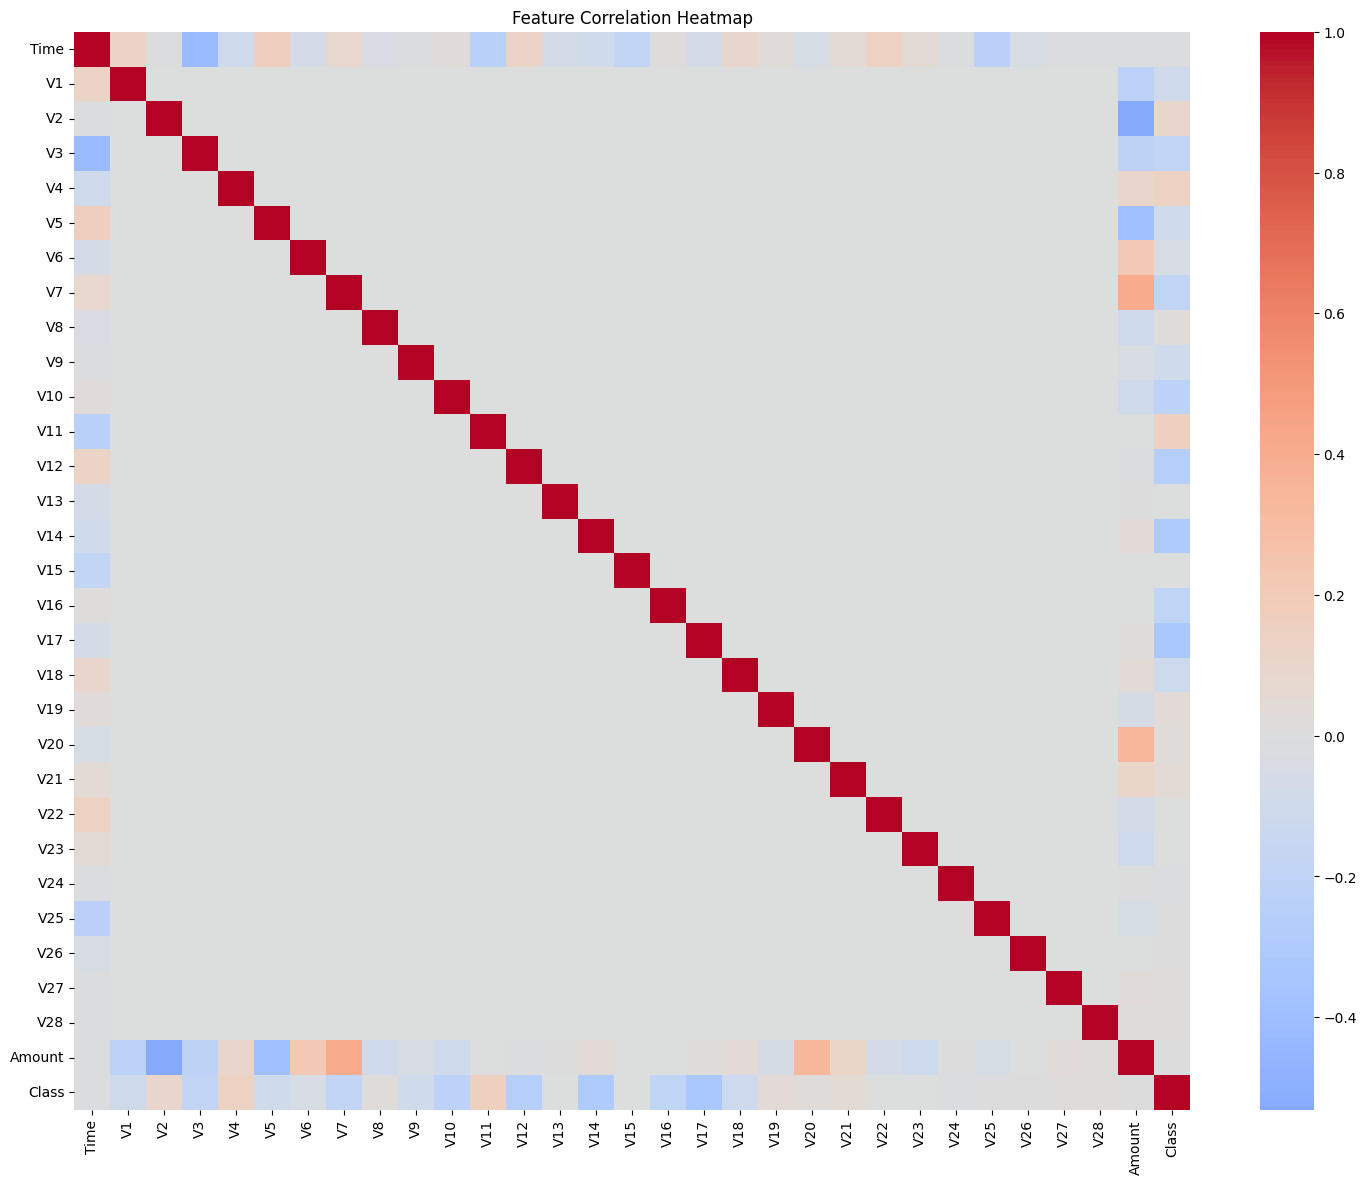

In [14]:
plt.figure(figsize=(18, 14))
correlation = df.corr()
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()


## 4.I) EDA Findings

The exploratory data analysis revealed the following findings:

1. The dataset contains 284,807 transactions.
2. There are 492 fraudulent transactions.
3. Fraudulent transactions represent a very small percentage of the dataset.
4. The dataset is highly imbalanced.
5. The Amount feature has a wide distribution.
6. Most numerical features are PCA-transformed features.
7. The dataset contains 1,081 duplicate records, which were identified during exploratory data analysis. These records were retained in the original dataset for this experiment.

Because of the significant class imbalance, accuracy alone will not be sufficient to evaluate model performance. Metrics such as precision, recall, F1-score, and Average Precision (AP) are more appropriate for evaluating fraud detection performance.

# 5. Data Preprocessing and Feature Engineering

## 5.A) Data Preprocessing

Before training the models, we need to prepare the dataset.

The target column is `Class`. The remaining columns are used as input features.

We will also create additional features from the transaction amount and elapsed time.


## 5.B) Create Additional Features

In [19]:
df_model = df.copy()

# Log transformation of transaction amount
df_model["Amount_log"] = np.log1p(df_model["Amount"])

# Experimental periodic transformations of elapsed transaction time.
# These are not verified transaction time-of-day features.
seconds_in_day = 86400
df_model["Time_sin"] = np.sin(
    2 * np.pi * (df_model["Time"] % seconds_in_day) / seconds_in_day
)
df_model["Time_cos"] = np.cos(
    2 * np.pi * (df_model["Time"] % seconds_in_day) / seconds_in_day
)

display(df_model.head())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_log,Time_sin,Time_cos
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,5.014760,0.000000,1.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,1.305626,0.000000,1.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,5.939276,0.000073,1.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,4.824306,0.000073,1.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,4.262539,0.000145,1.0


## 5.C) Define Features and Target

In [20]:
X = df_model.drop(columns=["Class", "Amount", "Time"])
y = df_model["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (284807, 31)
Target shape: (284807,)


## 5.D) Train, Validation, and Test Split

The dataset will be divided into three parts:

- 60% Training data
- 20% Validation data
- 20% Testing data

Stratified splitting preserves the proportion of fraudulent and legitimate transactions in each set.

The validation set will be used for model selection and threshold tuning. The test set will be kept separate for final evaluation.


## 5.E) Perform Dataset Splitting

In [21]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nFraud cases:")
print("Training:", int(y_train.sum()))
print("Validation:", int(y_val.sum()))
print("Testing:", int(y_test.sum()))


Training set: (170884, 31)
Validation set: (56961, 31)
Testing set: (56962, 31)

Fraud cases:
Training: 295
Validation: 98
Testing: 99


## 5.F) Verify Class Distribution

In [18]:
distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
})
display(distribution)


,Training,Validation,Testing
Class,,,
0,0.998274,0.99828,0.998262
1,0.001726,0.00172,0.001738


# 6. Model Selection and Training

## 6.A) Model Selection

We will train two supervised machine learning classification models:

1. Logistic Regression
2. Random Forest Classifier

Logistic Regression is a linear classification algorithm that provides a useful baseline.

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

Both models will use class weighting to help address the imbalanced dataset.


## 6.B) Train Logistic Regression Model

In [22]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        C=0.1,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression training completed.")


Logistic Regression training completed.


## 6.C) Train Random Forest Model

In [23]:
random_forest_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)
print("Random Forest training completed.")


Random Forest training completed.


# 7. Model Evaluation

## 7.A) Evaluation Metrics

We will evaluate the models using:

- Accuracy: Percentage of correctly classified transactions.
- Precision: Percentage of predicted fraud cases that are actually fraudulent.
- Recall: Percentage of actual fraud cases correctly identified.
- F1-score: Harmonic mean of precision and recall.
- ROC-AUC: Measures the model's ability to distinguish between classes.
- PR-AUC: Measures the precision-recall trade-off and is particularly useful for imbalanced datasets.

For fraud detection, recall and PR-AUC are especially important because missing fraudulent transactions can be costly.


## 7.B) Create Evaluation Function

In [24]:
def evaluate_model(model, X_data, y_data, threshold=0.5):
    probabilities = model.predict_proba(X_data)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_data, predictions),
        "Precision": precision_score(y_data, predictions, zero_division=0),
        "Recall": recall_score(y_data, predictions, zero_division=0),
        "F1-score": f1_score(y_data, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_data, probabilities),
        "PR-AUC": average_precision_score(y_data, probabilities)
    }


## 7.C) Evaluate Logistic Regression

In [25]:
logistic_results = evaluate_model(logistic_model, X_val, y_val)
print("Logistic Regression Validation Results:")
for metric, value in logistic_results.items():
    print(f"{metric}: {value:.4f}")


Logistic Regression Validation Results:
Accuracy: 0.9768
Precision: 0.0617
Recall: 0.8776
F1-score: 0.1154
ROC-AUC: 0.9807
PR-AUC: 0.6802


## 7.D) Evaluate Random Forest

In [26]:
rf_results = evaluate_model(random_forest_model, X_val, y_val)
print("Random Forest Validation Results:")
for metric, value in rf_results.items():
    print(f"{metric}: {value:.4f}")


Random Forest Validation Results:
Accuracy: 0.9994
Precision: 0.9012
Recall: 0.7449
F1-score: 0.8156
ROC-AUC: 0.9581
PR-AUC: 0.7881


## 7.E) Compare Initial Models

In [27]:
comparison = pd.DataFrame(
    [logistic_results, rf_results],
    index=["Logistic Regression", "Random Forest"]
)
display(comparison)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Logistic Regression,0.976844,0.061737,0.877551,0.115359,0.980667,0.680166
Random Forest,0.999421,0.901235,0.744898,0.815642,0.958135,0.788141


## 7.F) Visualize Model Comparison

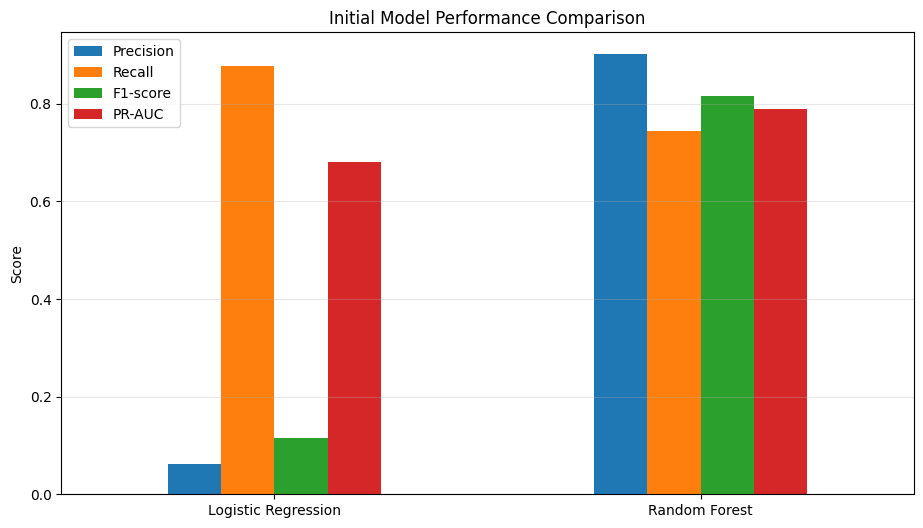

In [28]:
comparison[["Precision", "Recall", "F1-score", "PR-AUC"]].plot(
    kind="bar", figsize=(11, 6)
)
plt.title("Initial Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)
plt.show()


# 8. Hyperparameter Tuning

## 8.A) Introduction to Hyperparameter Tuning

Hyperparameter tuning helps improve model performance by testing different model configurations.

We will tune the Random Forest model using several combinations of hyperparameters. The validation PR-AUC score will be used to select the best configuration.


## 8.B) Define Hyperparameter Combinations

In [29]:
parameter_options = [
    {"n_estimators": 100, "max_depth": 10, "min_samples_split": 5, "min_samples_leaf": 2},
    {"n_estimators": 150, "max_depth": 15, "min_samples_split": 5, "min_samples_leaf": 2},
    {"n_estimators": 200, "max_depth": 20, "min_samples_split": 5, "min_samples_leaf": 2},
    {"n_estimators": 200, "max_depth": None, "min_samples_split": 10, "min_samples_leaf": 2},
    {"n_estimators": 250, "max_depth": 15, "min_samples_split": 10, "min_samples_leaf": 4}
]


## 8.C) Train and Compare Tuned Models

In [32]:
tuning_results = []

parameter_options = [
    {
        "n_estimators": 50,
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },
    {
        "n_estimators": 75,
        "max_depth": 12,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },
    {
        "n_estimators": 100,
        "max_depth": 15,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    }
]

best_model = None
best_pr_auc = -1
best_parameters = None

for i, params in enumerate(parameter_options, 1):

    print(f"Training model {i}/{len(parameter_options)}...")

    model = RandomForestClassifier(
        **params,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    val_probabilities = model.predict_proba(X_val)[:, 1]

    pr_auc = average_precision_score(
        y_val,
        val_probabilities
    )

    tuning_results.append({
        **params,
        "Validation_PR_AUC": pr_auc
    })

    print("Validation PR-AUC:", round(pr_auc, 4))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = model
        best_parameters = params

print("\nBest Parameters:", best_parameters)
print("Best Validation PR-AUC:", round(best_pr_auc, 4))

Training model 1/3...
Validation PR-AUC: 0.7568
Training model 2/3...
Validation PR-AUC: 0.7779
Training model 3/3...
Validation PR-AUC: 0.7866

Best Parameters: {'n_estimators': 100, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 2}
Best Validation PR-AUC: 0.7866


## 8.D) Display Hyperparameter Tuning Results

In [33]:
tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.sort_values(by="Validation_PR_AUC", ascending=False))


,n_estimators,max_depth,min_samples_split,min_samples_leaf,Validation_PR_AUC
2,100,15,5,2,0.786565
1,75,12,5,2,0.777911
0,50,10,5,2,0.756827


# 9. Decision Threshold Optimization

## 9.A) Introduction to Threshold Optimization

By default, binary classification models use a threshold of 0.5.

In fraud detection, a lower threshold may identify more fraudulent transactions. We will use the validation dataset to find the threshold that produces the highest F1-score. The test dataset will not be used during this optimization.


## 9.B) Calculate Validation Probabilities

In [34]:
val_probabilities = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, val_probabilities)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold_index = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_index]

print("Best Decision Threshold:", round(float(best_threshold), 4))
print("Best Validation F1-score:", round(float(f1_scores[best_threshold_index]), 4))


Best Decision Threshold: 0.3595
Best Validation F1-score: 0.8298


## 9.C) Visualize Precision, Recall, and F1-score

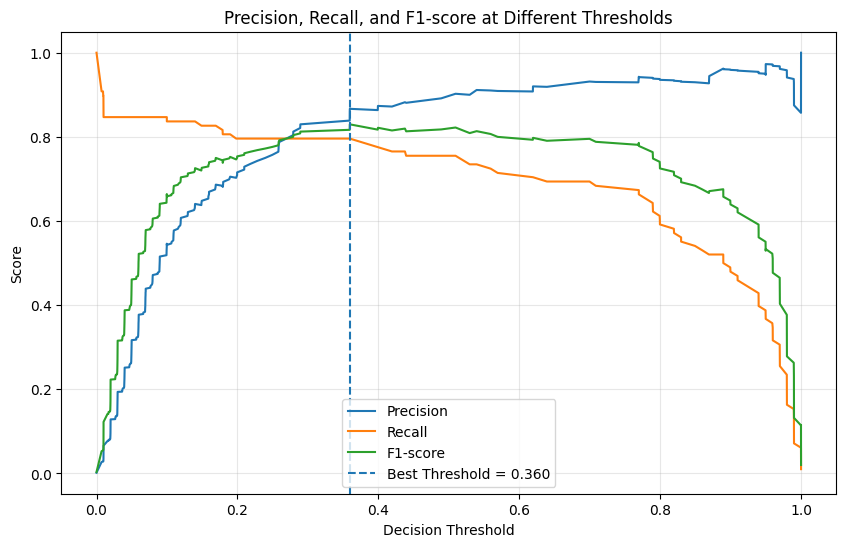

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score")
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1-score at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 10. Final Model Testing

## 10.A) Final Model Evaluation

After selecting the best Random Forest configuration and optimizing the decision threshold using the validation dataset, we will evaluate the model on the separate test dataset.

The test dataset has not been used for model training, hyperparameter tuning, or threshold optimization.


## 10.B) Generate Final Predictions

In [36]:
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)
print("Final test predictions generated.")


Final test predictions generated.


## 10.C) Calculate Final Evaluation Metrics

In [37]:
final_results = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}

print("Final Test Results:")
for metric, value in final_results.items():
    print(f"{metric}: {value:.4f}")


Final Test Results:
Accuracy: 0.9995
Precision: 0.8901
Recall: 0.8182
F1-score: 0.8526
ROC-AUC: 0.9516
PR-AUC: 0.8712


## 10.D) Display Confusion Matrix

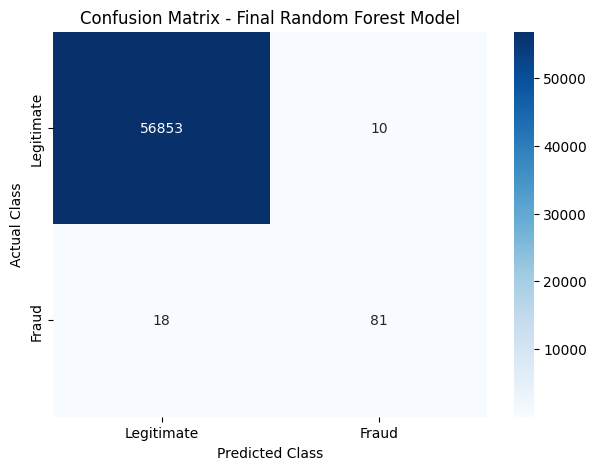

In [38]:
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Final Random Forest Model")
plt.show()


## 10.E) Classification Report

In [39]:
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.89      0.82      0.85        99

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962



## 10.F) Confusion Matrix Interpretation

- True Negative (TN): Legitimate transactions correctly identified.
- False Positive (FP): Legitimate transactions incorrectly classified as fraud.
- False Negative (FN): Fraudulent transactions incorrectly classified as legitimate.
- True Positive (TP): Fraudulent transactions correctly identified.

In fraud detection, false negatives are particularly important because they represent fraudulent transactions that the model failed to identify. False positives may cause legitimate transactions to be flagged for additional verification.


## 10.G) Display Feature Importance

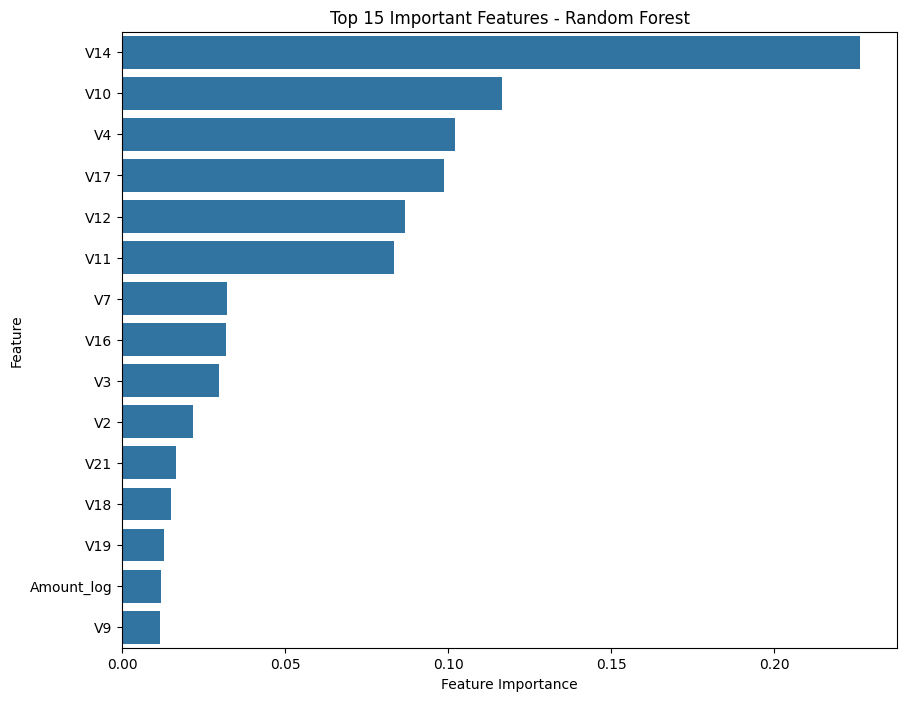

In [40]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()


## 10.H) Display Feature Importance Table

In [41]:
display(feature_importance.head(15))


,Feature,Importance
13,V14,0.226261
9,V10,0.116536
3,V4,0.102033
16,V17,0.098673
11,V12,0.086740
10,V11,0.083504
6,V7,0.032030
15,V16,0.032007
2,V3,0.029766
1,V2,0.021771


# 11. Model Analysis and Overfitting Check

## 11.A) Model Analysis

A model may perform very well on training data but poorly on unseen data. This is known as overfitting.

We will compare training and validation PR-AUC scores to check whether the selected model shows signs of overfitting.


## 11.B) Calculate Training and Validation PR-AUC

In [42]:
train_probabilities = best_model.predict_proba(X_train)[:, 1]
validation_probabilities = best_model.predict_proba(X_val)[:, 1]

train_pr_auc = average_precision_score(y_train, train_probabilities)
validation_pr_auc = average_precision_score(y_val, validation_probabilities)

print("Training PR-AUC:", round(train_pr_auc, 4))
print("Validation PR-AUC:", round(validation_pr_auc, 4))
print("Test PR-AUC:", round(final_results["PR-AUC"], 4))


Training PR-AUC: 0.9945
Validation PR-AUC: 0.7866
Test PR-AUC: 0.8712


## 11.C) Analyze the Performance Gap

In [43]:
performance_gap = train_pr_auc - validation_pr_auc

print("Training-Validation PR-AUC Gap:", round(performance_gap, 4))

if performance_gap > 0.10:
    print("The model may be overfitting.")
else:
    print("No large training-validation PR-AUC gap was observed.")


Training-Validation PR-AUC Gap: 0.208
The model may be overfitting.


## 11.D) Model Analysis Discussion

The training, validation, and testing scores help us understand how well the model generalizes to unseen data.

The model achieved a training **Average Precision (AP) of 0.9945**, compared with **0.7866** on the validation dataset. This is a substantial performance gap and suggests that the Random Forest model may be overfitting the training data.

The test Average Precision (AP) was **0.8712**, showing promising fraud detection performance on the held-out test dataset. However, the difference between training and validation performance indicates that the model's generalization should be interpreted with caution.

Further validation using cross-validation and time-based splitting would help assess how reliably the model performs on future transactions.

Potential improvements include:

1. Using shallower decision trees.
2. Increasing the minimum number of samples required at each leaf.
3. Applying stronger model regularization.
4. Performing more systematic hyperparameter optimization.
5. Evaluating the model using time-based validation.

Overall, the model demonstrates promising fraud detection capabilities, but additional validation and optimization are necessary before considering real-world deployment.

# 12. Model Saving and Prediction Demonstration

## 12.A) Model Saving

After completing the evaluation, we will save the selected Random Forest model.

The saved file will include the trained model, feature names, selected decision threshold, and selected hyperparameters.


## 12.B) Save Model and Configuration

In [44]:
model_artifact = {
    "model": best_model,
    "features": list(X_train.columns),
    "threshold": float(best_threshold),
    "best_parameters": best_parameters
}

joblib.dump(model_artifact, "credit_card_fraud_detection_model.pkl")
print("Model saved successfully.")


Model saved successfully.


## 12.C) Load the Saved Model

In [45]:
loaded_artifact = joblib.load("credit_card_fraud_detection_model.pkl")

loaded_model = loaded_artifact["model"]
loaded_features = loaded_artifact["features"]
loaded_threshold = loaded_artifact["threshold"]

print("Model loaded successfully.")
print("Decision threshold:", loaded_threshold)


Model loaded successfully.
Decision threshold: 0.35951372511436497


## 12.D) Test the Loaded Model

In [46]:
sample_transactions = X_test.iloc[:5][loaded_features]

sample_probabilities = loaded_model.predict_proba(sample_transactions)[:, 1]
sample_predictions = (sample_probabilities >= loaded_threshold).astype(int)

sample_results = pd.DataFrame({
    "Fraud Probability": sample_probabilities,
    "Predicted Class": sample_predictions
})

sample_results["Prediction"] = sample_results["Predicted Class"].map({
    0: "Legitimate",
    1: "Fraudulent"
})

display(sample_results)


,Fraud Probability,Predicted Class,Prediction
0,0.0,0,Legitimate
1,0.0,0,Legitimate
2,0.0,0,Legitimate
3,0.0,0,Legitimate
4,0.0,0,Legitimate


## 12.E) Download the Trained Model

In [47]:
from google.colab import files
files.download("credit_card_fraud_detection_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 13. Project Limitations and Future Improvements

## 13.A) Project Limitations

1. The dataset is highly imbalanced, with very few fraudulent transactions.
2. The dataset is based on transactions from 2013 and may not represent modern fraud patterns.
3. Most features are PCA-transformed, so their original meanings are not available.
4. Random train-test splitting does not fully simulate real-world future transaction prediction.
5. The model may require recalibration when transaction patterns change.
6. A prediction model alone cannot guarantee the prevention of financial fraud.


## 13.B) Future Improvements

1. Test additional algorithms such as XGBoost, LightGBM, and Gradient Boosting.
2. Explore resampling techniques such as SMOTE.
3. Perform time-based validation to better simulate real-world deployment.
4. Evaluate the financial cost of false positives and false negatives.
5. Use explainability tools such as SHAP to understand model predictions.
6. Monitor model performance and retrain it when fraud patterns change.
7. Integrate the model into a real-time transaction monitoring system.


# 14. Project Conclusion

## 14.A) Conclusion

In this project, we developed a machine learning solution for detecting fraudulent credit card transactions.

We performed exploratory data analysis, prepared the dataset, engineered additional features, and trained Logistic Regression and Random Forest classification models.

We addressed the class imbalance using class weighting and evaluated model performance using accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC.

We also performed hyperparameter tuning and optimized the classification threshold using validation data.

Finally, we evaluated the selected model on an independent test dataset and saved the trained model for future use.

This project demonstrates how machine learning can support financial fraud detection. However, further testing, real-world validation, and continuous monitoring would be necessary before deploying such a system in a production environment.


## 14.B) Final Results Summary

In [48]:
final_summary = pd.DataFrame({
    "Metric": list(final_results.keys()),
    "Score": list(final_results.values())
})
display(final_summary)


,Metric,Score
0,Accuracy,0.999508
1,Precision,0.890110
2,Recall,0.818182
3,F1-score,0.852632
4,ROC-AUC,0.951591
5,PR-AUC,0.871239


## 14.C) Final Model Configuration

In [49]:
print("Selected Model: Random Forest Classifier")
print("\nBest Hyperparameters:")
print(best_parameters)
print("\nSelected Decision Threshold:")
print(round(best_threshold, 4))
print("\nFinal Test Performance:")
for metric, value in final_results.items():
    print(f"{metric}: {value:.4f}")


Selected Model: Random Forest Classifier

Best Hyperparameters:
{'n_estimators': 100, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 2}

Selected Decision Threshold:
0.3595

Final Test Performance:
Accuracy: 0.9995
Precision: 0.8901
Recall: 0.8182
F1-score: 0.8526
ROC-AUC: 0.9516
PR-AUC: 0.8712


# 15. References

## 15.A) References

1. Kaggle - Credit Card Fraud Detection Dataset  
   https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

2. Scikit-learn Documentation  
   https://scikit-learn.org/stable/

3. Pandas Documentation  
   https://pandas.pydata.org/docs/

4. NumPy Documentation  
   https://numpy.org/doc/

5. Matplotlib Documentation  
   https://matplotlib.org/stable/

6. Seaborn Documentation  
   https://seaborn.pydata.org/
